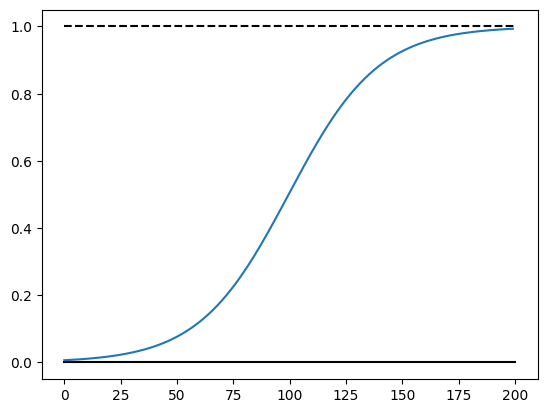

In [36]:
import numpy as np
import matplotlib.pyplot as plt
def sigmoid(z):
  return 1/ (1 +np.exp(-z))
z = np.linspace(-5,5,200)
plt.plot(sigmoid(z))
plt.plot([0,200],[0,0],'k-')
plt.plot([0,200],[1,1],'k--')

# Xavier and he initialization

In [37]:
import tensorflow as tf
dense = tf.keras.layers.Dense(50,activation='relu',
                              kernel_initializer='he_normal')



In [38]:
he_avg_init = tf.keras.initializers.VarianceScaling(scale=2,
                                                      mode='fan_avg', distribution='uniform')
dense = tf.keras.layers.Dense(50,activation='sigmoid',
                              kernel_initializer=he_avg_init)

# Nonsaturating Activvavtion Function

# leaky relu

In [39]:
def leaky_relu(z,alpha):
  return np.maximum(alpha*z,z)
z=np.linspace(-5,5,200)

In [40]:
leaky_relu = tf.keras.layers.LeakyReLU(negative_slope=0.2)
dense = tf.keras.layers.Dense(50,activation=leaky_relu,
                              kernel_initializer='he_normal')

In [41]:
model = tf.keras.models.Sequential([tf.keras.layers.Dense(50,kernel_initializer='he_normal'),
                                    tf.keras.layers.LeakyReLU(negative_slope=0.2)])

# ELU

In [42]:
dense = tf.keras.layers.Dense(50,activation='elu',
                              kernel_initializer='he_normal')

# SELU

ancaq chox deep neural networlerde istifade olunur, amma dense-den basqa hec bir layer olmamalidi ve data normalized olidi,lecun initializer olmalidi

In [43]:
dense = tf.keras.layers.Dense(50,activation='selu',
                              kernel_initializer='lecun_normal',)

In [44]:
tf.random.set_seed(42)
model = tf.keras.Sequential()
model.add(tf.keras.layers.Flatten(input_shape=[28,28]))
for layer in range(100):
  model.add(tf.keras.layers.Dense(100,activation='selu',kernel_initializer='lecun_normal'))
model.add(tf.keras.layers.Dense(10,activation='softmax'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [45]:
model.compile(loss='sparse_categorical_crossentropy',
              optimizer=tf.keras.optimizers.SGD(learning_rate=1e-3),
              metrics=['accuracy'])

In [46]:
from re import X
fashion_mnist=tf.keras.datasets.fashion_mnist.load_data()
(X_train_full,y_train_full),(X_test,y_test)=fashion_mnist
X_train,y_train=X_train_full[:-5000],y_train_full[:-5000]
X_valid,y_valid=X_train_full[-5000:],y_train_full[-5000:]
X_train,X_valid,X_test=X_train/255,X_valid/255,X_test/255

In [47]:
class_names=["T-shirt/top",
             "Trouser",
             "Pullover",
             "Dress",
             "Coat",
             "Sandal",
             "Shirt",
             "Sneaker Bag",
             "Ankle boot"]

In [48]:
pixel_means=X_train.mean(axis=0,keepdims=True)
pixel_stds=X_train.std(axis=0,keepdims=True)
X_train_scaled=(X_train-pixel_means)/pixel_stds
X_valid_scaled=(X_valid-pixel_means)/pixel_stds
X_test_scaled=(X_test-pixel_means)/pixel_stds

In [49]:
history = model.fit(X_train_scaled,y_train,epochs=5,validation_data=(X_valid_scaled,y_valid))

Epoch 1/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 40s 20ms/step - accuracy: 0.4354 - loss: 1.5028 - val_accuracy: 0.6964 - val_loss: 0.8612
Epoch 2/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 29s 17ms/step - accuracy: 0.6298 - loss: 1.0048 - val_accuracy: 0.5412 - val_loss: 1.1830
Epoch 3/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 30s 18ms/step - accuracy: 0.6701 - loss: 0.9055 - val_accuracy: 0.7516 - val_loss: 0.7106
Epoch 4/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 30s 17ms/step - accuracy: 0.7501 - loss: 0.6946 - val_accuracy: 0.7624 - val_loss: 0.6662
Epoch 5/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 30s 17ms/step - accuracy: 0.7514 - loss: 0.6734 - val_accuracy: 0.7554 - val_loss: 0.6616


In [50]:
tf.random.set_seed(42)

In [51]:
model = tf.keras.Sequential()
model.add(tf.keras.layers.Flatten(input_shape=[28,28]) )
for layer in range(100):
  model.add(tf.keras.layers.Dense(100,activation='relu',kernel_initializer='he_normal'))
model.add(tf.keras.layers.Dense(10,activation='softmax'))

In [52]:
model.compile(loss='sparse_categorical_crossentropy',
              optimizer=tf.keras.optimizers.SGD(learning_rate=1e-3),
              metrics=['accuracy'])

In [53]:
history = model.fit(X_train,y_train,epochs=5,validation_data=(X_valid,y_valid))

Epoch 1/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 33s 16ms/step - accuracy: 0.1760 - loss: 2.1067 - val_accuracy: 0.2714 - val_loss: 1.7978
Epoch 2/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 40s 16ms/step - accuracy: 0.4010 - loss: 1.4069 - val_accuracy: 0.3880 - val_loss: 1.5593
Epoch 3/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 29s 17ms/step - accuracy: 0.5199 - loss: 1.1027 - val_accuracy: 0.6206 - val_loss: 0.8674
Epoch 4/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 27s 16ms/step - accuracy: 0.5804 - loss: 0.9545 - val_accuracy: 0.6472 - val_loss: 0.8447
Epoch 5/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 27s 16ms/step - accuracy: 0.6271 - loss: 0.8300 - val_accuracy: 0.6520 - val_loss: 0.7746


# GELU,Swish and Mish

In [54]:
def swish(z,beta=1):
  return z*sigmoid(beta*z)

def approx_gelu(z):
  return swish(z,beta=1.702)
def softplus(z):
  return np.log(1 + np.log(z))
def mish(z):
  return z* np.tanh(softplus(z))

# Batch Normalization

In [55]:
tf.keras.backend.clear_session()
tf.random.set_seed(42)

In [56]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28,28]),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(300,activation='relu',kernel_initializer='he_normal'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(100,activation='relu',kernel_initializer='he_normal'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(10,activation='softmax')
])

In [57]:
[(var.name,var.trainable) for var in model.layers[1].variables]

[('gamma', True),
 ('beta', True),
 ('moving_mean', False),
 ('moving_variance', False)]

In [58]:
model.compile(loss='sparse_categorical_crossentropy',
              optimizer='sgd',
              metrics=['accuracy'])
model.fit(X_train,y_train,epochs=2,validation_data=(X_valid,y_valid))

Epoch 1/2
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.7498 - loss: 0.7439 - val_accuracy: 0.8492 - val_loss: 0.4044
Epoch 2/2
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.8533 - loss: 0.4110 - val_accuracy: 0.8634 - val_loss: 0.3685


In [59]:
tf.keras.backend.clear_session()
tf.random.set_seed(42)

Data activation functiona chatmazdan once normalize olmalidi
Batch Normalization Computer Vision uchun chox yaxshidi

In [60]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28,28]),
    tf.keras.layers.Dense(300,kernel_initializer='he_normal',use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.Dense(100,kernel_initializer='he_normal',use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.Dense(10,activation='softmax')
])


In [61]:
model.compile(loss='sparse_categorical_crossentropy', optimizer='sgd',
              metrics=['accuracy'])
model.fit(X_train,y_train,epochs=2,validation_data=(X_valid,y_valid))

Epoch 1/2
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.7359 - loss: 0.8213 - val_accuracy: 0.8442 - val_loss: 0.4320
Epoch 2/2
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8497 - loss: 0.4373 - val_accuracy: 0.8594 - val_loss: 0.3927



# Gradient Clipping for RNN

In [62]:
optimizer = tf.keras.optimizers.SGD(clipvalue=1.0)
model.compile(loss='sparse_categorical_crossentropy',optimizer=optimizer)

In [63]:
optimizer=tf.keras.optimizers.SGD(clipnorm=1.0)
model.compile(loss='sparse_categorical_crossentropy',optimizer=optimizer)

# Reusing Pretrained Layers

In [64]:
pos_class_id = class_names.index("Pullover")
neg_class_id = class_names.index("T-shirt/top")

def split_dataset(X, y):
  y_for_B = (y == pos_class_id) | (y == neg_class_id)
  y_A = y[~y_for_B]
  y_B = (y[y_for_B] == pos_class_id).astype(np.float32)
  old_class_ids = list(set(range(10)) - set([neg_class_id, pos_class_id]))
  for old_class_id, new_class_id in zip(old_class_ids, range(8)):
    y_A[y_A == old_class_id] = new_class_id
  return((X[~y_for_B],y_A),(X[y_for_B],y_B))

(X_train_A,y_train_A),(X_train_B,y_train_B)=split_dataset(X_train,y_train)
(X_valid_A,y_valid_A),(X_valid_B,y_valid_B)=split_dataset(X_valid,y_valid)
(X_test_A,y_test_A),(X_test_B,y_test_B)=split_dataset(X_test,y_test)
y_train_B = y_train_B[:200]
X_train_B = X_train_B[:200]

In [65]:
tf.random.set_seed(42)

model_A = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28,28]),
    tf.keras.layers.Dense(100,activation='relu',kernel_initializer='he_normal'),
    tf.keras.layers.Dense(100, activation='relu',kernel_initializer='he_normal'),
    tf.keras.layers.Dense(100,activation='relu',kernel_initializer='he_normal'),
    tf.keras.layers.Dense(8, activation='softmax')
])

model_A.compile(loss='sparse_categorical_crossentropy',
                optimizer=tf.keras.optimizers.SGD(learning_rate=1e-3),
                metrics=['accuracy'])

history = model_A.fit(X_train_A,y_train_A,epochs=20,validation_data=(X_valid_A,y_valid_A))
model_A.save('my_model_A.keras')


Epoch 1/20
1376/1376 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5231 - loss: 1.4362 - val_accuracy: 0.7644 - val_loss: 0.7048
Epoch 2/20
1376/1376 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7795 - loss: 0.6610 - val_accuracy: 0.8213 - val_loss: 0.5392
Epoch 3/20
1376/1376 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8313 - loss: 0.5228 - val_accuracy: 0.8486 - val_loss: 0.4609
Epoch 4/20
1376/1376 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8555 - loss: 0.4501 - val_accuracy: 0.8591 - val_loss: 0.4131
Epoch 5/20
1376/1376 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8688 - loss: 0.4037 - val_accuracy: 0.8701 - val_loss: 0.3819
Epoch 6/20
1376/1376 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8768 - loss: 0.3726 - val_accuracy: 0.8734 - val_loss: 0.3607
Epoch 7/20
1376/1376 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8822 - loss: 0.3507 - val_accuracy: 0.8769 - val_loss: 0.3452
Epoch 8/20
1376/1376 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8862 - loss: 0.3344 -

In [66]:
tf.random.set_seed(42)
model_B =tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28,28]),
    tf.keras.layers.Dense(100,activation='relu',
                          kernel_initializer='he_normal'),
    tf.keras.layers.Dense(100,activation='relu',
                          kernel_initializer='he_normal'),
    tf.keras.layers.Dense(100,activation='relu',
                          kernel_initializer='he_normal'),
    tf.keras.layers.Dense(1,activation='sigmoid')
])
model_B.compile(loss='binary_crossentropy',
                optimizer=tf.keras.optimizers.SGD(learning_rate=1e-3),
                metrics=['accuracy'])

# (X_train_A,y_train_A),(X_train_B,y_train_B)=split_dataset(X_train,y_train)
# (X_valid_A,y_valid_A),(X_valid_B,y_valid_B)=split_dataset(X_valid,y_valid)
# (X_test_A,y_test_A),(X_test_B,y_test_B)=split_dataset(X_test,y_test)
# y_train_B = y_train_B[:200]
# y_train_B = y_train_B[:200]
history = model_B.fit(X_train_B,y_train_B,epochs=20,
                      validation_data=(X_valid_B,y_valid_B))
model.evaluate(X_test_B,y_test_B)


Epoch 1/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - accuracy: 0.4232 - loss: 0.8827 - val_accuracy: 0.4797 - val_loss: 0.7953
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.4209 - loss: 0.8081 - val_accuracy: 0.4787 - val_loss: 0.7456
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.4413 - loss: 0.7561 - val_accuracy: 0.4797 - val_loss: 0.7101
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.4557 - loss: 0.7191 - val_accuracy: 0.5064 - val_loss: 0.6836
Epoch 5/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.5089 - loss: 0.6919 - val_accuracy: 0.5500 - val_loss: 0.6621
Epoch 6/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5490 - loss: 0.6695 - val_accuracy: 0.6212 - val_loss: 0.6436
Epoch 7/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5859 - loss: 0.6498 - val_accuracy: 0.6845 - val_loss: 0.6271
Epoch 8/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.6632 - loss: 0.6327 - val_accuracy: 0.7418 - val_loss: 0.6121


[3.3159961700439453, 0.38600000739097595]

In [67]:
X_train_B.shape

(200, 28, 28)

In [68]:
model_A = tf.keras.models.load_model("my_model_A.keras")
model_B_on_A = tf.keras.Sequential(model_A.layers[:-1])
model_B_on_A.add(tf.keras.layers.Dense(1,activation='sigmoid'))
tf.random.set_seed(42)
model_A_clone = tf.keras.models.clone_model(model_A)
model_A_clone.set_weights(model_A.get_weights())

In [69]:
model_B_on_A = tf.keras.Sequential(model_A_clone.layers[:-1])
model_B_on_A.add(tf.keras.layers.Dense(1,activation='sigmoid'))

In [70]:
for layer in model_B_on_A.layers[:-1]:
  layer.trainable=False
optimizer = tf.keras.optimizers.SGD(learning_rate=1e-3)
model_B_on_A.compile(loss='binary_crossentropy', optimizer=optimizer,
                     metrics=['accuracy'])
history = model_B_on_A.fit(X_train_B,y_train_B,epochs=4,
                           validation_data=(X_valid_B,y_valid_B))

Epoch 1/4
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - accuracy: 0.4301 - loss: 4.6054 - val_accuracy: 0.4847 - val_loss: 3.2533
Epoch 2/4
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.4301 - loss: 3.2203 - val_accuracy: 0.4847 - val_loss: 2.0210
Epoch 3/4
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.4301 - loss: 1.8942 - val_accuracy: 0.4847 - val_loss: 0.9845
Epoch 4/4
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.4494 - loss: 0.8843 - val_accuracy: 0.6627 - val_loss: 0.5622


In [71]:
for layer in model_B_on_A.layers[:-1]:
  layer.trainable = True

optimizer = tf.keras.optimizers.SGD(learning_rate=1e-3)
model_B_on_A.compile(loss='binary_crossentropy', optimizer=optimizer,
                     metrics=['accuracy'])
history = model_B_on_A.fit(X_train_B, y_train_B, epochs=16, validation_data=(X_valid_B, y_valid_B))

Epoch 1/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.7645 - loss: 0.5138 - val_accuracy: 0.8447 - val_loss: 0.4686
Epoch 2/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8915 - loss: 0.4361 - val_accuracy: 0.8684 - val_loss: 0.4317
Epoch 3/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8934 - loss: 0.3991 - val_accuracy: 0.8872 - val_loss: 0.4021
Epoch 4/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9338 - loss: 0.3691 - val_accuracy: 0.8991 - val_loss: 0.3774
Epoch 5/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9483 - loss: 0.3441 - val_accuracy: 0.9050 - val_loss: 0.3565
Epoch 6/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9483 - loss: 0.3228 - val_accuracy: 0.9120 - val_loss: 0.3386
Epoch 7/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9483 - loss: 0.3044 - val_accuracy: 0.9189 - val_loss: 0.3231
Epoch 8/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9483 - loss: 0.2883 - val_accuracy: 0.9258 - val_loss: 0.3095


In [72]:
model_B_on_A.evaluate(X_test_B, y_test_B)


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9380 - loss: 0.2457


[0.2518143951892853, 0.9304999709129333]

In [73]:
(1 - (100 - 93.67) / (100 - 88.33)) * 100

45.75835475578408

In [74]:
def build_model(seed=42):
  tf.random.set_seed(seed)
  return tf.keras.Sequential([
      tf.keras.layers.Flatten(input_shape=[28, 28]),
      tf.keras.layers.Dense(100, activation='relu',
                            kernel_initializer='he_normal'),
      tf.keras.layers.Dense(100, activation='relu',
                            kernel_initializer='he_normal'),
      tf.keras.layers.Dense(100, activation='relu',
                            kernel_initializer='he_normal'),
      tf.keras.layers.Dense(10, activation='softmax')
  ])

def build_and_train_model(optimizer):
  model = build_model()
  model.compile(loss='sparse_categorical_crossentropy',optimizer=optimizer,
                metrics=['accuracy'])
  return model.fit(X_train, y_train, epochs=10,
                   validation_data=(X_valid, y_valid))

# Momentum optimization

In [75]:
optimizer = tf.keras.optimizers.SGD(learning_rate=1e-3, momentum=0.9)

In [76]:
history_sgd = build_and_train_model(optimizer)

Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.6791 - loss: 0.9699 - val_accuracy: 0.8118 - val_loss: 0.5110
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8326 - loss: 0.4815 - val_accuracy: 0.8286 - val_loss: 0.4610
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8485 - loss: 0.4309 - val_accuracy: 0.8386 - val_loss: 0.4353
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8584 - loss: 0.4011 - val_accuracy: 0.8438 - val_loss: 0.4152
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8663 - loss: 0.3803 - val_accuracy: 0.8490 - val_loss: 0.4011
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8710 - loss: 0.3641 - val_accuracy: 0.8496 - val_loss: 0.3967
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8748 - loss: 0.3502 - val_accuracy: 0.8522 - val_loss: 0.3884
Epoch 8/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8785 - loss: 0.3376 - 

# Nesterov Accelerated Gradient

In [77]:
optimizer = tf.keras.optimizers.SGD(learning_rate=1e-3, momentum=0.9,
                                    nesterov = True)

In [78]:
history_nesterov = build_and_train_model(optimizer)

Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.6738 - loss: 0.9877 - val_accuracy: 0.8248 - val_loss: 0.4890
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8327 - loss: 0.4805 - val_accuracy: 0.8444 - val_loss: 0.4385
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8506 - loss: 0.4261 - val_accuracy: 0.8506 - val_loss: 0.4162
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8586 - loss: 0.3950 - val_accuracy: 0.8550 - val_loss: 0.3962
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8666 - loss: 0.3718 - val_accuracy: 0.8574 - val_loss: 0.3818
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8731 - loss: 0.3543 - val_accuracy: 0.8626 - val_loss: 0.3687
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8782 - loss: 0.3403 - val_accuracy: 0.8646 - val_loss: 0.3592
Epoch 8/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8831 - loss: 0.3286 - 

# AdaGrad

In [79]:
optimizer = tf.keras.optimizers.Adagrad(learning_rate=1e-3)         # her parametr uchun ayri learning_rate yaradir     amma global minimuma chatmir

In [80]:
history_adagrad = build_and_train_model(optimizer)

Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.5675 - loss: 1.3989 - val_accuracy: 0.7850 - val_loss: 0.6847
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7847 - loss: 0.6662 - val_accuracy: 0.8112 - val_loss: 0.5800
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8073 - loss: 0.5790 - val_accuracy: 0.8196 - val_loss: 0.5347
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8212 - loss: 0.5372 - val_accuracy: 0.8266 - val_loss: 0.5085
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8271 - loss: 0.5117 - val_accuracy: 0.8292 - val_loss: 0.4908
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8326 - loss: 0.4940 - val_accuracy: 0.8324 - val_loss: 0.4777
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8366 - loss: 0.4807 - val_accuracy: 0.8352 - val_loss: 0.4674
Epoch 8/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8388 - loss: 0.4702 - 

# RMSProp

In [81]:
optimizer = tf.keras.optimizers.RMSprop(learning_rate=1e-3, rho=0.9)

In [82]:
history_rmsprop = build_and_train_model(optimizer)

Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.7627 - loss: 0.6578 - val_accuracy: 0.8284 - val_loss: 0.4414
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8524 - loss: 0.4038 - val_accuracy: 0.8582 - val_loss: 0.4007
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8677 - loss: 0.3717 - val_accuracy: 0.8460 - val_loss: 0.4648
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8736 - loss: 0.3549 - val_accuracy: 0.8536 - val_loss: 0.4646
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8787 - loss: 0.3456 - val_accuracy: 0.8444 - val_loss: 0.5393
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8799 - loss: 0.3432 - val_accuracy: 0.8682 - val_loss: 0.4132
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8831 - loss: 0.3405 - val_accuracy: 0.8532 - val_loss: 0.4632
Epoch 8/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8826 - loss: 0.3380 - 

# Adam Optimization

In [83]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3, beta_1=0.9,    # momentum
                                     beta_2 = 0.999)  # RMSProp
history_adam = build_and_train_model(optimizer)

Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.7776 - loss: 0.6279 - val_accuracy: 0.8340 - val_loss: 0.4241
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8567 - loss: 0.3894 - val_accuracy: 0.8532 - val_loss: 0.3938
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.8727 - loss: 0.3446 - val_accuracy: 0.8528 - val_loss: 0.3960
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8839 - loss: 0.3166 - val_accuracy: 0.8572 - val_loss: 0.3962
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8897 - loss: 0.2971 - val_accuracy: 0.8560 - val_loss: 0.4366
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8947 - loss: 0.2826 - val_accuracy: 0.8588 - val_loss: 0.4051
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8996 - loss: 0.2722 - val_accuracy: 0.8684 - val_loss: 0.3779
Epoch 8/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9022 - loss: 0.2582 

# Adamax Optimization

In [84]:
optimizer = tf.keras.optimizers.Adamax(learning_rate=1e-3, beta_1=0.9,
                                       beta_2 = 0.999)
history_adamax = build_and_train_model(optimizer)

Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.7659 - loss: 0.6965 - val_accuracy: 0.8330 - val_loss: 0.4445
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8563 - loss: 0.4110 - val_accuracy: 0.8514 - val_loss: 0.3932
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8695 - loss: 0.3665 - val_accuracy: 0.8594 - val_loss: 0.3745
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8805 - loss: 0.3346 - val_accuracy: 0.8642 - val_loss: 0.3659
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8863 - loss: 0.3143 - val_accuracy: 0.8624 - val_loss: 0.3674
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8925 - loss: 0.2992 - val_accuracy: 0.8654 - val_loss: 0.3626
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8967 - loss: 0.2852 - val_accuracy: 0.8662 - val_loss: 0.3589
Epoch 8/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9008 - loss: 0.2731 -

In [85]:
# nadam, adamw, muon arasdir

# Nadam -- Nesterov + Adam

# AdamW Optimization

In [86]:
optimizer = tf.keras.optimizers.AdamW(weight_decay=1e-5, learning_rate=1e-3,
                                      beta_1=0.9, beta_2=0.999)
history_adamw = build_and_train_model(optimizer)                                # chox deep network ishledirikse AdamW de ishlede bilerik

Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.7658 - loss: 0.6674 - val_accuracy: 0.8374 - val_loss: 0.4254
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8577 - loss: 0.3910 - val_accuracy: 0.8396 - val_loss: 0.4073
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8717 - loss: 0.3503 - val_accuracy: 0.8524 - val_loss: 0.3883
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8829 - loss: 0.3192 - val_accuracy: 0.8624 - val_loss: 0.3649
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8886 - loss: 0.2985 - val_accuracy: 0.8610 - val_loss: 0.3732
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8948 - loss: 0.2825 - val_accuracy: 0.8734 - val_loss: 0.3471
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8988 - loss: 0.2688 - val_accuracy: 0.8720 - val_loss: 0.3929
Epoch 8/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9030 - loss: 0.2588 -

# Learning rate scheduling

# Power Scheduling

In [87]:
# DEPRECATED:
# optimizer = tf.keras.optimizers.legacy.SGD(learning_rate=0.01, decay=1e-4)

In [88]:
# REOMMENDED:
lr_schedule = tf.keras.optimizers.schedules.InverseTimeDecay(
    initial_learning_rate=0.01,
    decay_steps=10_000,
    decay_rate=1.0,
    staircase=False
)

optimizer = tf.keras.optimizers.SGD(learning_rate=lr_schedule)

In [89]:
history_power_scheduling = build_and_train_model(optimizer)


Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.6820 - loss: 0.9462 - val_accuracy: 0.8276 - val_loss: 0.4964
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8267 - loss: 0.4948 - val_accuracy: 0.8366 - val_loss: 0.4523
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8450 - loss: 0.4410 - val_accuracy: 0.8430 - val_loss: 0.4335
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8548 - loss: 0.4121 - val_accuracy: 0.8490 - val_loss: 0.4212
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8596 - loss: 0.3924 - val_accuracy: 0.8530 - val_loss: 0.4075
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8654 - loss: 0.3775 - val_accuracy: 0.8584 - val_loss: 0.3961
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8694 - loss: 0.3658 - val_accuracy: 0.8618 - val_loss: 0.3865
Epoch 8/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8733 - loss: 0.3561 -

# Exponential Scheduling

# Avoiding Overfitting Through Regularization

In [90]:
layers = tf.keras.layers.Dense(100, activation='relu',
                              kernel_initializer='he_normal',
                              kernel_regularizer=tf.keras.regularizers.l2(0.01))

In [91]:
tf.random.set_seed(42)

In [92]:
from functools import partial

RegularizedDense = partial(tf.keras.layers.Dense,
                          activation='relu',
                          kernel_initializer='he_normal',
                          kernel_regularizer= tf.keras.regularizers.l2(0.01))

model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    RegularizedDense(100),
    RegularizedDense(100),
    RegularizedDense(10, activation='softmax')
])

In [93]:
optimizer = tf.keras.optimizers.SGD(learning_rate=2e-2)
model.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer,
              metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=2,
                    validation_data=(X_valid, y_valid))

Epoch 1/2
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.6962 - loss: 4.0934 - val_accuracy: 0.8208 - val_loss: 1.8566
Epoch 2/2
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8107 - loss: 1.6210 - val_accuracy: 0.8218 - val_loss: 1.1160


# Dropout

In [94]:
tf.random.set_seed(42)


In [95]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    tf.keras.layers.Dropout(rate=0.2),                                        # burda pixellerin 20%-ini atiririq
    tf.keras.layers.Dense(100, activation='relu',
                          kernel_initializer='he_normal'),
    tf.keras.layers.Dropout(rate=0.2),                                        # burda amma neuronlarin 20%-ini
    tf.keras.layers.Dense(100, activation='relu',
                          kernel_initializer='he_normal'),
    tf.keras.layers.Dropout(rate=0.2),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [96]:
optimizer = tf.keras.optimizers.SGD(learning_rate=1e-2,
                                    momentum=0.9)
model.compile(loss='sparse_categorical_crossentropy',
              optimizer=optimizer,
              metrics=['accuracy'])
model.fit(X_train, y_train, epochs=10,
          validation_data=(X_valid, y_valid))

Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.6746 - loss: 0.8923 - val_accuracy: 0.8342 - val_loss: 0.4483
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8044 - loss: 0.5375 - val_accuracy: 0.8426 - val_loss: 0.4382
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8238 - loss: 0.4867 - val_accuracy: 0.8454 - val_loss: 0.3993
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8313 - loss: 0.4593 - val_accuracy: 0.8558 - val_loss: 0.3771
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8383 - loss: 0.4405 - val_accuracy: 0.8574 - val_loss: 0.3814
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8407 - loss: 0.4337 - val_accuracy: 0.8676 - val_loss: 0.3615
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8439 - loss: 0.4165 - val_accuracy: 0.8640 - val_loss: 0.3555
Epoch 8/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8519 - loss: 0.4074 - 